In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import re

from analysis import small_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [2]:
import sys
sys.path.append('../')
import pipeline_utility as pu

In [16]:
data = pd.read_csv("../experiments/full_pipeline/final_data.csv")

# SELECT WHICH FISH TO ANALYZE
selected_fish = "fish14"

# Filter and deduplicate barcodes for selected fish
fish_data = (
    data.query('fish == @selected_fish and sample == 1')#[data['fish'] == selected_fish]
    .groupby('barcode')
    .agg(count=('barcode', 'count'), samples=('sample', lambda x: ','.join(x.unique().astype(str))))
    .reset_index()
)

print(f"Analyzing {len(fish_data)} unique barcodes from {selected_fish}")

Analyzing 12 unique barcodes from fish14


In [17]:
UNEDITED = "NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE"

def parse_barcode(barcode_string):
    return barcode_string.split("_")

def parse_edit_details(edit_string):
    """
    Format is:
      Deletion:      lengthD+pos        e.g. 54D+199
      Insertion:     lengthI+pos        e.g. 3I+34
      Substitution:  lengthS+pos+BASES  e.g. 4S+169+CAGA
    Returns list of (pos, length, etype) tuples.
    """
    if edit_string == "NONE":
        return []
    results = []
    clean = edit_string.split("&")[0].strip()
    m = re.search(r'(\d+)([DIS])\+(\d+)', clean)
    if m:
        first  = int(m.group(1))
        etype  = {'D': 'deletion', 'I': 'insertion', 'S': 'substitution'}[m.group(2)]
        second = int(m.group(3))
        if etype == 'substitution':
            # format: lengthS+pos+BASES — first=length, second=pos
            pos, length = second, first
        else:
            # format: lengthD+pos or lengthI+pos — first=length, second=pos
            pos, length = second, first
    results.append((pos, length, etype))
    return results

def detect_spanning_edits(parsed_sites):
    """
    Identifies edits that span multiple consecutive sites (identical edit string repeated).
    Returns a dict: {start_site_idx: (end_site_idx_inclusive, pos, length, etype)}
    Sites covered by a span after the first are marked in 'skip_sites' set.
    """
    N = len(parsed_sites)
    spans = {}   # start_idx -> (end_idx, pos, length, etype)
    skip = set() # site indices that are continuations of a span

    i = 0
    while i < N:
        if i in skip or parsed_sites[i] == "NONE":
            i += 1
            continue
        edits = parse_edit_details(parsed_sites[i])
        if not edits:
            i += 1
            continue
        pos, length, etype = edits[0]
        # Look ahead for consecutive identical edit strings
        j = i + 1
        while j < N and parsed_sites[j] == parsed_sites[i]:
            j += 1
        if j > i + 1:
            # Spanning edit from site i to site j-1
            spans[i] = (j - 1, pos, length, etype)
            for k in range(i + 1, j):
                skip.add(k)
            i = j
        else:
            i += 1

    return spans, skip

In [18]:
# Remove unedited if present, but don't require it
other_barcodes = fish_data[fish_data['barcode'] != UNEDITED]['barcode'].tolist()

has_unedited = (fish_data['barcode'] == UNEDITED).any()
if has_unedited:
    all_barcodes = [UNEDITED] + other_barcodes
else:
    print(f"Note: {selected_fish} has no unedited barcode — proceeding without it.")
    all_barcodes = other_barcodes

N_SITES = 10
parsed = {b: b.split("_") for b in all_barcodes}

# Known absolute bp coordinates for each site [start, end] (inclusive)
SITE_COORDS = [
    (22,  44),
    (49,  71),
    (76,  98),
    (103, 125),
    (130, 152),
    (157, 179),
    (184, 206),
    (211, 233),
    (238, 260),
    (265, 287),
]
SITE_LENGTHS = [end - start + 1 for start, end in SITE_COORDS]

# Total span from first base of site 1 to last base of site 10
TOTAL_START = SITE_COORDS[0][0]
TOTAL_END   = SITE_COORDS[-1][1]
TOTAL_SPAN  = TOTAL_END - TOTAL_START  # used for proportional x mapping

def bp_to_x(bp):
    """Convert an absolute bp position to x coordinate in data units."""
    return (bp - TOTAL_START) / TOTAL_SPAN * N_SITES

def site_start_x(site_idx):
    return bp_to_x(SITE_COORDS[site_idx][0])

def site_end_x(site_idx):
    return bp_to_x(SITE_COORDS[site_idx][1])

print(f"Total bp span: {TOTAL_START}–{TOTAL_END} ({TOTAL_SPAN} bp)")
print(f"Site lengths: {SITE_LENGTHS}")
print(f"Barcodes to plot: {len(all_barcodes)}")

Note: fish14 has no unedited barcode — proceeding without it.
Total bp span: 22–287 (265 bp)
Site lengths: [23, 23, 23, 23, 23, 23, 23, 23, 23, 23]
Barcodes to plot: 12


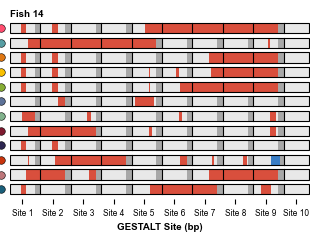

In [19]:
SITE_COLORS  = {"insertion": "#3A7EC6", "deletion": "#D94F3D",
                "substitution": "#E8A838", "none": "#E8E8E8"}
LINKER_COLOR = "#A8A8A8"
ROW_HEIGHT   = 0.7
ROW_GAP      = 0.3
UNIT         = N_SITES

n_barcodes = len(all_barcodes)

# Fixed heatmap dimensions in inches
HEATMAP_WIDTH_IN  = 3
HEATMAP_HEIGHT_IN = max(0.2, n_barcodes * 0.15)

LABEL_WIDTH_IN  = 2.0
LEGEND_WIDTH_IN = 1.5
TOP_IN          = 0.6
BOTTOM_IN       = 0.6

fig_width  = LABEL_WIDTH_IN + HEATMAP_WIDTH_IN + LEGEND_WIDTH_IN
fig_height = TOP_IN + HEATMAP_HEIGHT_IN + BOTTOM_IN

fig, ax = plt.subplots(figsize=(fig_width, fig_height))
dot_transform = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)

left   = LABEL_WIDTH_IN   / fig_width
bottom = BOTTOM_IN         / fig_height
width  = HEATMAP_WIDTH_IN  / fig_width
height = HEATMAP_HEIGHT_IN / fig_height
ax.set_position([left, bottom, width, height])

order, color_dict = pu.barcodes_to_colors(data.query('fish == @selected_fish and sample == 1'))
dot_colors = [color_dict[bc] for bc in order]

for row_idx, barcode in enumerate(order):
    y     = (n_barcodes - 1 - row_idx) * (ROW_HEIGHT + ROW_GAP)
    sites = parsed[barcode]
    spans, skip = detect_spanning_edits(sites)

    # Linker background across full row
    ax.add_patch(mpatches.Rectangle(
        (0, y), UNIT, ROW_HEIGHT,
        linewidth=0, facecolor=LINKER_COLOR
    ))

    # Unedited background for each site region
    for site_idx in range(N_SITES):
        sx = site_start_x(site_idx)
        ex = site_end_x(site_idx)
        ax.add_patch(mpatches.Rectangle(
            (sx, y), ex - sx, ROW_HEIGHT,
            linewidth=0, facecolor=SITE_COLORS["none"]
        ))

    # Draw edits
    for site_idx in range(N_SITES):
        site_start_bp, site_end_bp = SITE_COORDS[site_idx]
        raw_edit = sites[site_idx] if site_idx < len(sites) else "NONE"

        # Spanning edit starting at this site
        if site_idx in spans:
            end_site, pos, length, etype = spans[site_idx]
            abs_start_bp = pos
            abs_end_bp   = SITE_COORDS[end_site][1]
            x_start = bp_to_x(abs_start_bp)
            x_end   = bp_to_x(abs_end_bp)
            ax.add_patch(mpatches.Rectangle(
                (x_start, y), max(x_end - x_start, 0.02), ROW_HEIGHT,
                linewidth=0, facecolor=SITE_COLORS[etype]
            ))
            continue

        if site_idx in skip:
            continue

        # Normal single-site edit
        edits = parse_edit_details(raw_edit)
        for (pos, length, etype) in edits:
            if etype == "insertion":
                # Insertions have no reference length — draw at position,
                # width scaled proportionally to inserted length within the site
                site_len_bp = SITE_COORDS[site_idx][1] - SITE_COORDS[site_idx][0]
                frac_width  = min(length / site_len_bp, 1.0)
                x_start     = bp_to_x(max(pos, site_start_bp))
                x_width     = frac_width * (site_end_x(site_idx) - site_start_x(site_idx))
                ax.add_patch(mpatches.Rectangle(
                    (x_start, y), max(x_width, 0.02), ROW_HEIGHT,
                    linewidth=0, facecolor=SITE_COLORS[etype]
                ))
            else:
                abs_start_bp = pos
                abs_end_bp   = abs_start_bp + length
                abs_start_bp = min(max(abs_start_bp, site_start_bp), site_end_bp)
                abs_end_bp   = min(abs_end_bp, site_end_bp)
                x_start = bp_to_x(abs_start_bp)
                x_end   = bp_to_x(abs_end_bp)
                ax.add_patch(mpatches.Rectangle(
                    (x_start, y), max(x_end - x_start, 0.02), ROW_HEIGHT,
                    linewidth=0, facecolor=SITE_COLORS[etype]
                ))

    # Outer border for the whole barcode row
    ax.add_patch(mpatches.Rectangle(
        (0, y), UNIT, ROW_HEIGHT,
        linewidth=0.8, edgecolor='black', facecolor='none'
    ))

    # Site dividers contained within row
    for site_idx in range(1, N_SITES):
        sx = site_start_x(site_idx)
        ax.plot([sx, sx], [y, y + ROW_HEIGHT],
                color='black', linewidth=0.8, zorder=3)

    row_center_y = y + ROW_HEIGHT / 2
    DOT_X = -0.03   # in axes coords, just left of heatmap
    ax.scatter(
        [DOT_X], [row_center_y],
        transform=dot_transform,
        s=30,                    # marker size in points^2, tweak to taste
        color=dot_colors[row_idx],
        edgecolors='black',
        linewidths=0.4,
        clip_on=False,
        zorder=5
    )

# Axis formatting
ax.set_xlim(0, UNIT + 0.05)
total_height = n_barcodes * (ROW_HEIGHT + ROW_GAP)
ax.set_ylim(-ROW_GAP, total_height)
ax.set_xticks([site_start_x(i) + (site_end_x(i) - site_start_x(i)) / 2
               for i in range(N_SITES)])
#ax.set_xticklabels([f"Site {i+1}\n{SITE_COORDS[i][0]}–{SITE_COORDS[i][1]}"
                    #for i in range(N_SITES)], fontsize=6)
ax.set_xticklabels([f"Site {i+1}" for i in range(N_SITES)], fontsize=6)
# ax.set_yticks([(n_barcodes - 1 - i) * (ROW_HEIGHT + ROW_GAP) + ROW_HEIGHT / 2
#                for i in range(n_barcodes)])
ax.set_yticks([])
# ax.set_yticklabels(all_barcodes, fontsize=6)
ax.set_xlabel("GESTALT Site (bp)", fontsize=7, fontweight = 'bold')
ax.set_title(f"Fish {selected_fish[4:]}", fontsize=7, fontweight='bold', loc = 'left', pad = 0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False)

# Legend
legend_elements = [
    mpatches.Patch(facecolor="#D94F3D", label="Deletion"),
    mpatches.Patch(facecolor="#3A7EC6", label="Insertion"),
    mpatches.Patch(facecolor="#E8A838", label="Substitution"),
    mpatches.Patch(facecolor=SITE_COLORS["none"], label="Unedited", edgecolor="#CCCCCC"),
    mpatches.Patch(facecolor=LINKER_COLOR, label="Linker"),
]
legend_x = (LABEL_WIDTH_IN + HEATMAP_WIDTH_IN + 0.2) / fig_width
legend_y = (BOTTOM_IN + HEATMAP_HEIGHT_IN) / fig_height
# ax.legend(handles=legend_elements,
#           loc='upper left',
#           bbox_to_anchor=(legend_x, legend_y),
#           bbox_transform=fig.transFigure,
#           frameon=False, fontsize=6)

plt.savefig(f"images/barcode_edit_maps/barcode_editmap_{selected_fish}_short.svg", bbox_inches='tight', transparent=True)
plt.savefig(f"images/barcode_edit_maps/barcode_editmap_{selected_fish}_short.png", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
# Count total barcodes across all fish (excluding unedited)
filtered       = data[data['barcode'] != UNEDITED]
all_fish_barcodes = filtered['barcode'].unique()
total_barcodes = filtered.groupby('fish')['barcode'].nunique().sum()

# Initialize per-bp counters across the full reference span
bp_range = range(TOTAL_START, TOTAL_END + 1)
deletion_counts      = {bp: 0 for bp in bp_range}
insertion_counts     = {bp: 0 for bp in bp_range}
substitution_counts  = {bp: 0 for bp in bp_range}

for barcode in all_fish_barcodes:
    sites = barcode.split("_")
    spans, skip = detect_spanning_edits(sites)

    for site_idx in range(min(N_SITES, len(sites))):
        site_start_bp, site_end_bp = SITE_COORDS[site_idx]

        if site_idx in spans:
            end_site, pos, length, etype = spans[site_idx]
            if etype == "deletion":
                abs_start = pos
                abs_end   = min(abs_start + length, SITE_COORDS[end_site][1])
                for bp in range(max(abs_start, TOTAL_START), min(abs_end, TOTAL_END) + 1):
                    if bp in deletion_counts:
                        deletion_counts[bp] += 1
            elif etype == "insertion":
                bp = max(min(pos, site_end_bp), site_start_bp)
                if bp in insertion_counts:
                    insertion_counts[bp] += 1
            elif etype == "substitution":
                abs_start = pos
                abs_end   = abs_start + length
                abs_start = min(max(abs_start, site_start_bp), site_end_bp)
                abs_end   = min(abs_end, site_end_bp)
                for bp in range(abs_start, abs_end):   # exclusive end — no +1
                    if bp in substitution_counts:
                        substitution_counts[bp] += 1
            continue

        if site_idx in skip:
            continue

        edits = parse_edit_details(sites[site_idx])
        for (pos, length, etype) in edits:
            if etype == "deletion":
                abs_start = pos
                abs_end   = abs_start + length
                abs_start = min(max(abs_start, site_start_bp), site_end_bp)
                abs_end   = min(abs_end, site_end_bp)
                for bp in range(abs_start, abs_end + 1):
                    if bp in deletion_counts:
                        deletion_counts[bp] += 1
            elif etype == "insertion":
                bp = max(min(pos, site_end_bp), site_start_bp)
                if bp in insertion_counts:
                    insertion_counts[bp] += 1
            elif etype == "substitution":
                abs_start = pos
                abs_end   = abs_start + length
                abs_start = min(max(abs_start, site_start_bp), site_end_bp)
                abs_end   = min(abs_end, site_end_bp)
                for bp in range(abs_start, abs_end):   # exclusive end — no +1
                    if bp in substitution_counts:
                        substitution_counts[bp] += 1

# Convert to percentage
bp_positions = list(bp_range)
del_pct  = [deletion_counts[bp]     / total_barcodes * 100 for bp in bp_positions]
ins_pct  = [insertion_counts[bp]    / total_barcodes * 100 for bp in bp_positions]
sub_pct  = [substitution_counts[bp] / total_barcodes * 100 for bp in bp_positions]

# Plot
HEATMAP_WIDTH_IN  = 6.0
LABEL_WIDTH_IN    = 0.8
LEGEND_WIDTH_IN   = 1.2
TOP_IN            = 0.6
BOTTOM_IN         = 0.6
PLOT_HEIGHT_IN    = 1.5

fig_width  = LABEL_WIDTH_IN + HEATMAP_WIDTH_IN + LEGEND_WIDTH_IN
fig_height = TOP_IN + PLOT_HEIGHT_IN + BOTTOM_IN

fig2, ax2 = plt.subplots(figsize=(fig_width, fig_height))

left   = LABEL_WIDTH_IN   / fig_width
bottom = BOTTOM_IN         / fig_height
width  = HEATMAP_WIDTH_IN  / fig_width
height = PLOT_HEIGHT_IN    / fig_height
ax2.set_position([left, bottom, width, height])

# Shade linker background across full range, then overlay site regions
ax2.axvspan(TOTAL_START, TOTAL_END, color=LINKER_COLOR, zorder=0)
for site_idx in range(N_SITES):
    sx = SITE_COORDS[site_idx][0]
    ex = SITE_COORDS[site_idx][1]
    ax2.axvspan(sx, ex, color='#E8E8E8', zorder=1)

# Plot line for each edit type
def mask_isolated_zeros(pct_list):
    """
    Mask zeros outside nonzero runs, but preserve one zero on each side
    of every run so the line touches the x-axis before disappearing.
    """
    result = [np.nan] * len(pct_list)
    nonzero_indices = [i for i, v in enumerate(pct_list) if v > 0]
    if not nonzero_indices:
        return result
    # Find contiguous runs of nonzero values
    runs = []
    run_start = nonzero_indices[0]
    prev = nonzero_indices[0]
    for idx in nonzero_indices[1:]:
        if idx > prev + 1:
            runs.append((run_start, prev))
            run_start = idx
        prev = idx
    runs.append((run_start, prev))
    # For each run, copy values and add one zero buffer on each side
    for start, end in runs:
        buf_start = max(0, start - 1)
        buf_end   = min(len(pct_list) - 1, end + 1)
        for i in range(buf_start, buf_end + 1):
            result[i] = pct_list[i]  # zero buffer positions get their true value (0)
    return result

def mask_zeros(pct_list):
    """Replace all zeros with nan — use for substitutions only."""
    return [v if v > 0 else np.nan for v in pct_list]

del_masked = mask_isolated_zeros(del_pct)
ins_masked = mask_isolated_zeros(ins_pct)
sub_masked = mask_zeros(sub_pct)

ax2.plot(bp_positions, del_masked, color="#D94F3D", linewidth=1.5, label="Deletion",     zorder=2, solid_capstyle='butt')
ax2.plot(bp_positions, ins_masked, color="#3A7EC6", linewidth=1.5, label="Insertion",    zorder=2, solid_capstyle='butt')
ax2.plot(bp_positions, sub_masked, color="#E8A838", linewidth=1.5, label="Substitution", zorder=2, solid_capstyle='butt')

# Site boundary lines
for site_idx in range(N_SITES):
    for edge_bp in SITE_COORDS[site_idx]:
        ax2.axvline(x=edge_bp, color='black', linewidth=0.6, zorder=3)

ax2.set_xlim(TOTAL_START, TOTAL_END)
ax2.set_ylim(0, max(max(del_pct), max(ins_pct), max(sub_pct)) * 1.2)
ax2.set_xticks([s + (e - s) / 2 for s, e in SITE_COORDS])
ax2.set_xticklabels([f"Site {i+1}" for i in range(N_SITES)])
ax2.tick_params(axis='both', labelsize=6)
ax2.set_ylabel("Edited (%)", fontsize=6)
ax2.set_title("Edit Frequency Across All Fish", fontsize=8, fontweight='bold')
for spine in ['top', 'right']:
    ax2.spines[spine].set_visible(False)

ax2.legend(loc='upper left',
           bbox_to_anchor=((LABEL_WIDTH_IN + HEATMAP_WIDTH_IN + 0.1) / fig_width,
                           (BOTTOM_IN + PLOT_HEIGHT_IN) / fig_height),
           bbox_transform=fig2.transFigure,
           frameon=False, fontsize=7)

plt.savefig("images/barcode_edit_maps/barcode_editmap_frequency_summary.svg", bbox_inches='tight', transparent=True)
plt.savefig("images/barcode_edit_maps/barcode_editmap_frequency_summary.png", dpi=300, bbox_inches='tight', transparent=True)